In [1]:
import torch
from PPO.PPO import PPO
from PPO.PPO import run_test_env
from PPO.wrappers import make_atari, CropScreen, wrap_deepmind, wrap_pytorch, ExcludeFireAction

In [2]:
# HYPER-PARAMETERS #
max_frames       = int(1e7)
max_rewards      = None
num_steps        = 128
num_envs         = 16
batch_size       = 512
ppo_epochs       = 4
lr               = 'lin_2.5e-4'
clip_range       = 0.1
vf_coef          = 0.5
ent_coef         = 0.01
gamma            = 0.99
lam              = 0.7
clip_grad_norm   = 0.5
std_decay        = True
clip_log_std     = None
log_every        = 250
runs_for_episode = 5
test_episodes    = 3
log_file         = './logs/Breakout-v4.pth'

In [3]:
def make_env():
    def _thunk():
        env = make_atari('BreakoutNoFrameskip-v4')
        env = CropScreen(env, top=32, bottom=225, left=8, right=160)
        env = wrap_deepmind(env, episode_life=True, clip_rewards=True, frame_stack=True)
        env = ExcludeFireAction(env)
        env = wrap_pytorch(env)
        return env
    return _thunk

def make_test_env(render_mode=None):
    env = make_atari('BreakoutNoFrameskip-v4', render_mode=render_mode)
    env = CropScreen(env, top=32, bottom=225, left=8, right=160)
    env = wrap_deepmind(env, episode_life=True, clip_rewards=False, frame_stack=True)
    env = ExcludeFireAction(env)
    env = wrap_pytorch(env)
    return env

obs_space: Box(0, 255, (4, 84, 84), uint8)
act_space: Discrete(3)


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


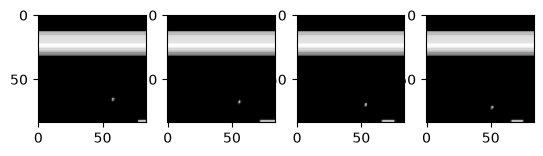

In [4]:
import matplotlib.pyplot as plt

env = make_env()()
print('obs_space:', env.observation_space)
print('act_space:', env.action_space)
obs, _ = env.reset()
for i in range(10):
    obs, r, terminated, truncated, _ = env.step(torch.randint(0, 3, (1,)).item())
fig, axs = plt.subplots(1, 4)
axs[0].imshow(obs[0], cmap='gray')
axs[1].imshow(obs[1], cmap='gray')
axs[2].imshow(obs[2], cmap='gray')
axs[3].imshow(obs[3], cmap='gray')

In [ ]:
ppo = PPO(make_env, device='auto')

In [ ]:
# Run this cell to load a previous checkpoint
ppo.load(log_file)

In [ ]:
ppo.learn(max_frames, max_rewards=max_rewards, num_steps=num_steps, num_envs=num_envs, batch_size=batch_size,
          ppo_epochs=ppo_epochs, clip_range=clip_range, lr=lr, vf_coef=vf_coef, ent_coef=ent_coef,
          gamma=gamma, lam=lam, clip_grad_norm=clip_grad_norm, std_decay=std_decay, clip_log_std=clip_log_std,
          log_every=log_every, log_file=log_file, test_env=make_test_env(), runs_for_episode=runs_for_episode, test_episodes=test_episodes)

In [ ]:
del ppo

In [5]:
ppo = PPO(make_env, device='cpu')

In [6]:
ppo.load(log_file)

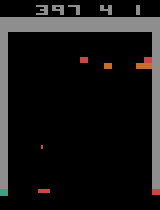

KeyboardInterrupt: 

In [7]:
env = make_test_env(render_mode='rgb_array')
runs_for_episode = 3
n_episode = 1

mean_reward = run_test_env(env=env, model=ppo, runs_for_episode=runs_for_episode, n_episodes=n_episode, vis=True, deterministic=False)
env.close()

print('Mean reward over %i episodes = %f' % (n_episode, mean_reward))